# Data-Informed Airport Secondary Baggage-Inspection Queue Simulation

**Research question:** For a hypothetical shared FIFO baggage-inspection queue with service durations informed by published airport observations, how do the number of inspection stations, passenger arrival rate, and inspection speed affect average waiting time?

**Scope:** One pooled FIFO queue feeding identical parallel stations. The cleaned sample of 162 *observed manual baggage-check durations* calibrates the service distribution; **arrivals and pooling are scenario assumptions, not observations**. Results are not validated airport staffing recommendations.

**Methods:** Next-event discrete-event simulation (M/M/c analytical baseline; M/G/c empirical-service simulation), input modelling / random variate generation, Monte Carlo replication and confidence intervals. This notebook contains numerical verification, input sensitivity, uncertainty and reproducible figures. AI assistance used in development; student verification and logs are required.

## 1. Problem definition and objectives

**Decision:** Find the minimum number of tested inspection stations with a replication-level **upper 95% confidence bound** on modelled mean queue wait below an **illustrative 0.5-minute target**, at fixed assumed passenger demand. This target is **not** an official service standard.

**Experimental conditions:** Poisson arrivals with rates 0.40, 0.65, 0.85 passengers/minute; 1–3 stations; observed service durations with 0.8, 1.0, 1.2 multipliers. Stable steady-state cases are interpreted separately from overload cases. Other outcomes: probability of waiting more than 0.5 minute, mean queue wait and nominal utilisation.

**Lecture areas:** (i) next-event DES and FIFO queues, (ii) empirical input modelling and exponential/empirical random variates, (iii) Monte Carlo/LLN with independent replications and confidence intervals.

## 2. Model, assumptions and mathematical foundations

A single infinite-capacity FIFO queue feeds $c$ identical non-preemptive stations. Simulation events are **arrival** and **service completion**. The simulation clock advances directly to the next event (no fixed time step). Times are in **minutes** unless specified otherwise.

**Baseline M/M/c:** Independent exponential interarrival times with mean $1/\lambda$ and exponential services with mean $1/\mu$ per station. Define $a=\lambda/\mu$ and $\rho=\lambda/(c\mu)<1$. Under steady state,

$$P_0=\left[\sum_{k=0}^{c-1}\frac{a^k}{k!}+\frac{a^c}{c!(1-\rho)}\right]^{-1},\quad P(\mathrm{wait})=\frac{a^c P_0}{c!(1-\rho)},\quad E[W_q]=\frac{P(\mathrm{wait})}{c\mu-\lambda}. $$

**Data-informed M/G/c:** Interarrival times remain exponential, while independently resampled observed positive baggage-check durations $S$ give general service times. The stability check is $\rho=\lambda E[S]/c<1$. The M/M/c Erlang-C waiting formula **does not apply to this empirical service model**. A steady-state mean waiting time for $\rho\ge 1$ is undefined; finite-run outputs in such cases must not be labelled steady-state performance.

**Statistical output:** Each independent replication discards a specified number of initial customers from its *waiting-time observations* to reduce start-empty bias. A 95% Student-$t$ confidence interval is computed **across independent replication means**, not across dependent customer waits in a single run. Fixed-length runs can retain bias near capacity; Monte Carlo intervals condition on assumed arrivals, queue structure and the selected inspection sample.

**Key limitations:** Dataset contains service-stage timestamps for selected manual baggage inspections, not arrivals to the hypothetical pooled queue. Service records may be dependent within observation sessions, and identical stations, no abandonment and no priority are assumptions.

## 3. Implementation

In [1]:
# Reproducible dependencies in the first code cell; free Colab already has these packages.
import importlib.util, subprocess, sys
for package in ("numpy", "pandas", "scipy", "matplotlib"):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", package])
from pathlib import Path
FIGURES=Path("Figures"); RESULTS=Path("Results")
FIGURES.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)

# Standalone Colab cell; Python queue engine is identical to src/queue_model.py.
# Source provenance: ChatGPT-generated, human review required.
import math, statistics, csv, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

"""Single FIFO queue with parallel identical inspection stations; units: minutes."""
from collections import deque
from dataclasses import dataclass
from math import inf
import random

@dataclass
class Result:
    arrivals: int
    completed: int
    mean_wait: float
    fraction_wait_over_target: float
    mean_queue_length: float
    utilisation: float
    waits: list

def simulate(arrivals, services, servers=2, target_wait=5.0):
    """Deterministic event-trace engine; arrivals and services are equal-length sequences."""
    if servers < 1 or len(arrivals) != len(services):
        raise ValueError("Invalid server count or trace lengths")
    if any(b < a for a,b in zip(arrivals,arrivals[1:])):
        raise ValueError("Arrivals must be sorted")
    if any(s <= 0 for s in services):
        raise ValueError("Service durations must be positive")
    n=len(arrivals)
    if not n:
        return Result(0,0,0,0,0,0,[])
    idle=list(range(servers))
    finish=[inf]*servers
    queue=deque()
    waits=[0.0]*n
    i=0; done=0; now=0.; queue_area=0.; busy_area=0.
    while done<n:
        next_arrival=arrivals[i] if i<n else inf
        next_depart=min(finish)
        t=min(next_arrival,next_depart)
        queue_area+=len(queue)*(t-now)
        busy_area+=sum(f<inf for f in finish)*(t-now)
        now=t
        # Departures before arrivals at tied timestamps.
        departing=[j for j,f in enumerate(finish) if f==now]
        for j in departing:
            finish[j]=inf; done+=1; idle.append(j)
        while i<n and arrivals[i]==now:
            queue.append(i); i+=1
        idle.sort()
        while idle and queue:
            j=idle.pop(0)
            customer=queue.popleft()
            waits[customer]=now-arrivals[customer]
            finish[j]=now+services[customer]
    duration=now  # Time-averaged metrics over [0, final departure], matching browser.
    return Result(n,done,sum(waits)/n,sum(w>target_wait for w in waits)/n,
                  queue_area/duration if duration else 0,
                  busy_area/(servers*duration) if duration else 0,waits)

def random_trace(rate_per_minute, mean_service_minutes, n, seed):
    if rate_per_minute<=0 or mean_service_minutes<=0: raise ValueError("Rates must be positive")
    rng=random.Random(seed); t=0.; arrivals=[]; services=[]
    for _ in range(n):
        t+=rng.expovariate(rate_per_minute)
        arrivals.append(t)
        services.append(rng.expovariate(1/mean_service_minutes))
    return arrivals,services



In [2]:
def mmc_wait(lambda_rate, mu_rate, servers):
    if not 0 < lambda_rate < servers * mu_rate:
        raise ValueError("Requires stable M/M/c parameters")
    a = lambda_rate / mu_rate
    rho = a / servers
    p0 = 1 / (sum(a**k/math.factorial(k) for k in range(servers)) + a**servers/(math.factorial(servers)*(1-rho)))
    pw = a**servers * p0/(math.factorial(servers)*(1-rho))
    return pw/(servers*mu_rate-lambda_rate)

def replication(rate, mean_service, servers, n, seed, warmup=1000):
    arrivals, services = random_trace(rate, mean_service, n + warmup, seed)
    result = simulate(arrivals, services, servers=servers)
    # Warm-up is discarded from customer waiting observations only.
    # Area/time statistics require a separate steady-state window implementation.
    return float(np.mean(result.waits[warmup:])), float(np.mean(np.asarray(result.waits[warmup:]) > 5))

def mean_ci(values, alpha=0.05):
    values = np.asarray(values, dtype=float)
    if len(values) < 2: raise ValueError("At least two replications required")
    avg = float(values.mean())
    half = float(student_t.ppf(1-alpha/2, len(values)-1) * values.std(ddof=1)/np.sqrt(len(values)))
    return avg, avg-half, avg+half


## 4. Verification
Visible hand-calculated event trace, deterministic zero-wait case, and analytical M/M/$c$ comparison with a predeclared tolerance. Analytical agreement is statistical, not an exact per-run identity.
Cross-language metric conventions: time-weighted queue length and utilisation use the observation window from simulation time zero through the final departure. The deterministic browser reference includes all arrivals and departures, while its live counters are interim statistics.


In [3]:
hand = simulate([0, 1, 1.5], [3, 2, 1], servers=1)
assert np.allclose(hand.waits, [0, 2, 3.5])
assert simulate([0, 10, 20], [1, 1, 1], servers=1).mean_wait == 0
assert random_trace(0.8, 1, 10, 7) == random_trace(0.8, 1, 10, 7)
print("Hand trace, zero-wait and seed reproducibility: PASS")

Hand trace, zero-wait and seed reproducibility: PASS


In [4]:
rate, mean_service, servers = 0.8, 1.0, 2
samples = [replication(rate, mean_service, servers, 12000, seed=100+i)[0] for i in range(30)]
estimate, lower, upper = mean_ci(samples)
analytic = mmc_wait(rate, 1/mean_service, servers)
print(f"Simulated Wq = {estimate:.4f} min; 95% CI [{lower:.4f}, {upper:.4f}]")
print(f"M/M/c analytical Wq = {analytic:.4f} min")
assert abs(estimate - analytic) < 0.035, "M/M/c comparison outside predeclared 0.035-minute tolerance"

Simulated Wq = 0.1944 min; 95% CI [0.1898, 0.1991]
M/M/c analytical Wq = 0.1905 min


## 5. Baseline M/M/c scenario comparison

At the same assumed arrival rate, compare exponential-service staffing scenarios with independent replication means and confidence intervals. The next section separately calibrates empirical service times. The M/M/c mean wait is an analytical benchmark **only** for the exponential baseline.

,stations,mean_wait,ci_low,ci_high,p_wait_over_5,utilization_theory
0,1,3.977800,3.752525,4.203075,0.291060,0.800000
1,2,0.193371,0.187432,0.199311,0.000433,0.400000
2,3,0.023441,0.022127,0.024755,0.000000,0.266667
3,4,0.003057,0.002730,0.003383,0.000000,0.200000


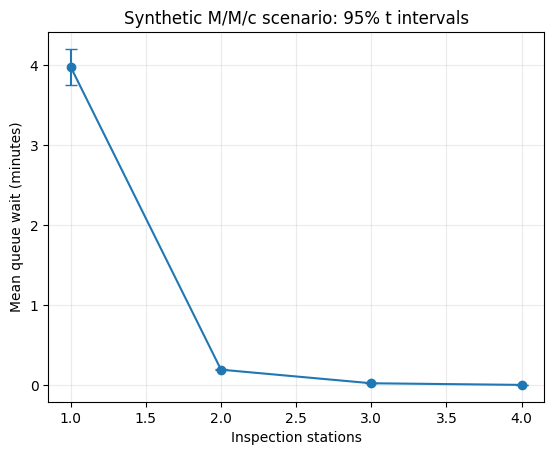

In [5]:
records=[]
for c in [1,2,3,4]:
    if rate >= c/mean_service: continue
    rep=[replication(rate, mean_service, c, 5000, 5000+c*100+i) for i in range(30)]
    w=mean_ci([v[0] for v in rep]); tail=mean_ci([v[1] for v in rep])
    records.append(dict(stations=c, mean_wait=w[0], ci_low=w[1], ci_high=w[2], p_wait_over_5=tail[0], utilization_theory=rate*mean_service/c))
results=pd.DataFrame(records)
display(results)
plt.errorbar(results.stations,results.mean_wait,yerr=[results.mean_wait-results.ci_low,results.ci_high-results.mean_wait],fmt='o-',capsize=4)
plt.xlabel('Inspection stations');plt.ylabel('Mean queue wait (minutes)');plt.title('Synthetic M/M/c scenario: 95% t intervals');plt.grid(alpha=.25);plt.savefig(FIGURES/'mmc_staffing_comparison.png',dpi=180,bbox_inches='tight');plt.show()
results.to_csv(RESULTS/'mmc_staffing_comparison.csv',index=False)

## 6. Data calibration and empirical model (X4)

The source is the 4TU.ResearchData *Airport Security Checkpoint Data* associated with Janssen et al. (2020). The extracted field pair describes **Time Start Baggage Check** and **Time End Baggage Check**. The calibration CSV contains 162 positive durations from documented worksheets. Two additional unlisted worksheets were excluded at cleaning time; see the repository's `data/README.md` and `data/cleaning_audit.csv` for the exact decision trail.

The data determine the **service-time input distribution only**. They do *not* establish passenger arrival rates, queue size, shared-server architecture or real waiting times. These latter quantities remain scenario assumptions.

The notebook first attempts a local checkout path; otherwise it reads the versioned project CSV from the public GitHub repository. If network access is unavailable, clone the project and run from its root. Do not silently substitute synthetic source data.

Clean baggage checks: n=162, mean=59.97s, median=42.00s


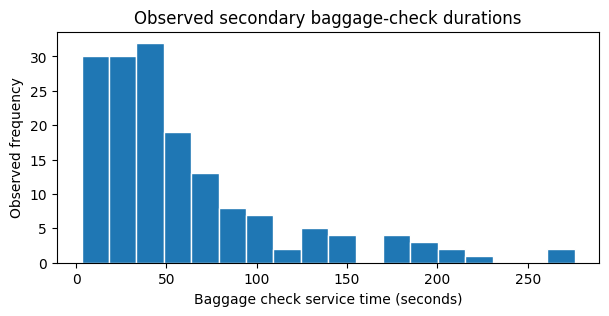

In [6]:
# This public source file must be committed to GitHub along with the notebook.
# GitHub-hosted Colab and local execution both use the same cleaned CSV.
from pathlib import Path
import urllib.request
candidates=[Path('data/cleaned_baggage_check_durations.csv'), Path('../data/cleaned_baggage_check_durations.csv')]
local_path=next((q for q in candidates if q.exists()), None)
url='https://raw.githubusercontent.com/KawanRupasinghe/airport-baggage-queue/main/data/cleaned_baggage_check_durations.csv'
if local_path is not None:
    observed=pd.read_csv(local_path)
else:
    observed=pd.read_csv(io.BytesIO(urllib.request.urlopen(url,timeout=20).read()))
durations_minutes=observed.service_seconds.to_numpy(dtype=float)/60.0
assert len(durations_minutes)==162
assert np.all(np.isfinite(durations_minutes)) and np.all(durations_minutes>0)
print(f'Clean baggage checks: n={len(durations_minutes)}, mean={np.mean(durations_minutes)*60:.2f}s, median={np.median(durations_minutes)*60:.2f}s')
assert set(['sheet','service_seconds']).issubset(observed.columns)
assert observed.sheet.nunique()==13
observed[['sheet','service_seconds']].groupby('sheet').agg(['count','mean','median']).to_csv(RESULTS/'session_input_summary.csv')
fig,ax=plt.subplots(figsize=(7,3));ax.hist(durations_minutes*60,bins=18,edgecolor='white');ax.set(xlabel='Baggage check service time (seconds)',ylabel='Observed frequency',title='Observed secondary baggage-check durations');plt.savefig(FIGURES/'observed_service_histogram.png',dpi=180,bbox_inches='tight');plt.show()

In [7]:
def empirical_replication(arrival_rate,stations,n,seed,warmup=500):
    rng=np.random.default_rng(seed)
    interarrival=rng.exponential(1/arrival_rate,size=n+warmup)
    arrival_times=np.cumsum(interarrival).tolist()
    services=rng.choice(durations_minutes,size=n+warmup,replace=True).tolist()
    result=simulate(arrival_times,services,servers=stations)
    post=np.asarray(result.waits[warmup:])
    return float(post.mean()),float(np.mean(post>2.0))

# Replication-level confidence intervals—not passenger-level pseudo-replication.
service_mean=float(durations_minutes.mean())
# Diagnostic equal-utilisation comparison: these rates change with station count.
# Do not use it to choose staffing at a fixed demand; the X5 section does that.
records=[]
for load in [0.40,0.65,0.85]:
    for stations in [1,2,3]:
        arrival_rate=load*stations/service_mean
        estimates=[empirical_replication(arrival_rate,stations,2500,seed=1500+int(load*100)*100+stations*40+i) for i in range(24)]
        lo,lower,upper=mean_ci([x[0] for x in estimates])
        records.append(dict(target_utilisation=load,stations=stations,arrival_rate_per_minute=arrival_rate,mean_wait_min=lo,ci_low=lower,ci_high=upper,p_wait_gt_2_min=np.mean([x[1] for x in estimates])))
empirical_results=pd.DataFrame(records)
display(empirical_results.round(4))
empirical_results.to_csv(RESULTS/'empirical_equal_utilisation_diagnostic.csv',index=False)


,target_utilisation,stations,arrival_rate_per_minute,mean_wait_min,ci_low,ci_high,p_wait_gt_2_min
0,0.40,1,0.4002,0.6021,0.5791,0.6251,0.1105
1,0.40,2,0.8004,0.1697,0.1611,0.1783,0.0151
2,0.40,3,1.2006,0.0685,0.0641,0.0729,0.0025
3,0.65,1,0.6503,1.6741,1.5865,1.7617,0.3094
4,0.65,2,1.3007,0.6864,0.6529,0.7199,0.1154
5,0.65,3,1.9510,0.3599,0.3302,0.3895,0.0410
6,0.85,1,0.8504,5.4267,4.6655,6.1880,0.6155
7,0.85,2,1.7009,2.3125,2.1103,2.5147,0.3940
8,0.85,3,2.5513,1.3311,1.1745,1.4877,0.2554


### X4 extension: descriptive distribution analysis and calibration uncertainty

We report distribution quantiles, standard deviation, coefficient of variation, and compare the observed density to a fitted exponential **illustration** (not a formal goodness-of-fit acceptance test). The primary model continues to sample the **empirical durations** directly.

Two bootstrap analyses quantify input-mean uncertainty: (a) resampling individual observations, implicitly treating them as exchangeable, and (b) a cluster bootstrap that resamples the 13 observed sessions, preserving each selected session's records. With only 13 clusters and nonrandom session selection, neither method establishes a population-level interval for all baggage checks.

,observations,mean_s,median_s,sample_sd_s,cv,p90_s,p95_s,min_s,max_s
0,162,59.969,42.0,54.081,0.902,134.9,183.95,3.0,276.0


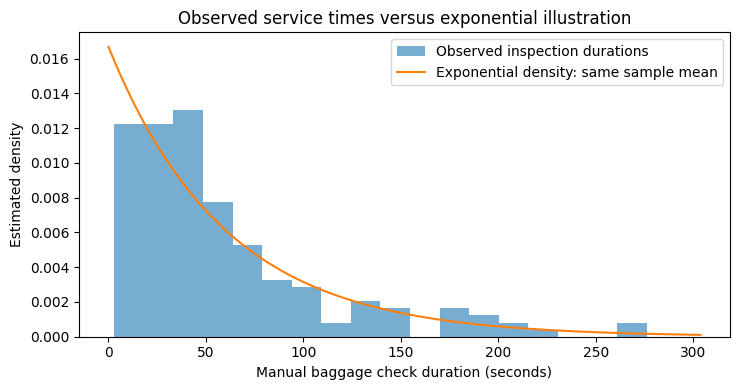

,method,lower_95_s,upper_95_s
0,observation bootstrap,51.957,68.599
1,session cluster bootstrap,52.603,67.098


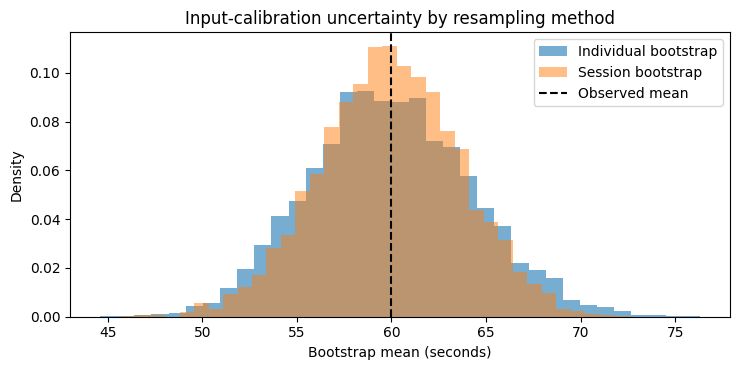

In [8]:
# Descriptive statistics and comparison to an exponential model with the same observed mean.
seconds=observed.service_seconds.to_numpy(dtype=float)
assert seconds.size==162 and np.all(np.isfinite(seconds)) and np.all(seconds>0)
service_summary=pd.DataFrame([{
    'observations':len(seconds),'mean_s':seconds.mean(),'median_s':np.median(seconds),
    'sample_sd_s':seconds.std(ddof=1),'cv':seconds.std(ddof=1)/seconds.mean(),
    'p90_s':np.percentile(seconds,90),'p95_s':np.percentile(seconds,95),
    'min_s':seconds.min(),'max_s':seconds.max()}])
display(service_summary.round(3))
service_summary.to_csv(RESULTS/'service_distribution_statistics.csv',index=False)
fig,ax=plt.subplots(figsize=(7.5,4))
ax.hist(seconds,bins=18,density=True,alpha=.6,label='Observed inspection durations')
x=np.linspace(0,seconds.max()*1.1,400)
ax.plot(x,np.exp(-x/seconds.mean())/seconds.mean(),label='Exponential density: same sample mean')
ax.set(xlabel='Manual baggage check duration (seconds)',ylabel='Estimated density',title='Observed service times versus exponential illustration')
ax.legend();fig.tight_layout();fig.savefig(FIGURES/'service_distribution_comparison.png',dpi=200);plt.show()

# Reproducible bootstrap of the mean; group labels come from the source session tabs.
sessions={key:group.service_seconds.to_numpy(dtype=float) for key,group in observed.groupby('sheet')}
assert len(sessions)==13
names=list(sessions)
rng=np.random.default_rng(20261118)
B=5000
observation_means=np.empty(B);cluster_means=np.empty(B)
for b in range(B):
    observation_means[b]=rng.choice(seconds,size=len(seconds),replace=True).mean()
    sampled_names=rng.choice(names,size=len(names),replace=True)
    cluster_means[b]=np.concatenate([sessions[name] for name in sampled_names]).mean()
bootstrap_intervals=pd.DataFrame([
    {'method':'observation bootstrap','lower_95_s':np.percentile(observation_means,2.5),'upper_95_s':np.percentile(observation_means,97.5)},
    {'method':'session cluster bootstrap','lower_95_s':np.percentile(cluster_means,2.5),'upper_95_s':np.percentile(cluster_means,97.5)},
])
display(bootstrap_intervals.round(3))
bootstrap_intervals.to_csv(RESULTS/'bootstrap_service_mean_intervals.csv',index=False)
fig,ax=plt.subplots(figsize=(7.5,3.8))
ax.hist(observation_means,bins=35,density=True,alpha=.6,label='Individual bootstrap')
ax.hist(cluster_means,bins=35,density=True,alpha=.5,label='Session bootstrap')
ax.axvline(seconds.mean(),c='black',ls='--',label='Observed mean')
ax.set(xlabel='Bootstrap mean (seconds)',ylabel='Density',title='Input-calibration uncertainty by resampling method');ax.legend();fig.tight_layout()
fig.savefig(FIGURES/'service_mean_bootstrap.png',dpi=200);plt.show()


### Independent FIFO implementation verification

We check a second implementation based on the earliest available station against the event-list engine, using identical deterministic arrival and service traces. This is independent *logic verification* of FIFO waiting calculations; it does not validate the real airport's queue structure. It supplements the analytic M/M/c check above.

In [9]:
def independent_fifo_waits(arrivals, services, stations):
    """Independent multi-server FCFS waiting-time algorithm (minutes)."""
    if stations<1 or len(arrivals)!=len(services):raise ValueError('Invalid queue dimensions')
    available=np.zeros(stations,dtype=float)
    waits=np.zeros(len(arrivals),dtype=float)
    for i,(arr,duration) in enumerate(zip(arrivals,services)):
        station=int(np.argmin(available))
        start=max(float(arr),available[station])
        waits[i]=start-arr
        available[station]=start+duration
    return waits

fixtures=[([0,1,1.5],[3,2,1],1),([5,6,6.5],[3,2,1],1),
          ([2,2,2,3.2,8],[1,4,2,1.5,2],2),([0,10,20],[1,1,1],1)]
for arrivals,services,station_count in fixtures:
    queue_result=simulate(arrivals,services,servers=station_count)
    np.testing.assert_allclose(queue_result.waits,independent_fifo_waits(arrivals,services,station_count),atol=1e-10)
    assert queue_result.arrivals==queue_result.completed
for station_count in [1,2,3]:
    rg=np.random.default_rng(100+station_count)
    arrivals=np.cumsum(rg.exponential(1/.65,size=200))
    durations=rg.choice(durations_minutes,size=200,replace=True)
    np.testing.assert_allclose(simulate(arrivals.tolist(),durations.tolist(),station_count).waits,
                               independent_fifo_waits(arrivals,durations,station_count),atol=1e-10)
print('Independent FIFO reference: 7 deterministic/randomised test traces passed')


Independent FIFO reference: 7 deterministic/randomised test traces passed


### Interpretation of the empirical input experiments

The previous **equal-utilisation** diagnostic deliberately adjusts demand with station count and therefore is **not** the staffing decision at a fixed arrival rate. The X5 section below fixes arrival intensity while changing stations. The empirical-service model resamples each observed duration with replacement; its output waiting times are hypothetical and cannot be validated from this source dataset alone.

## 7. Stronger verification: direct analytical Monte Carlo error scaling (X2)

For a stable M/M/1 queue, $W_q=\lambda/[\mu(\mu-\lambda)]$. We use $\lambda=0.55$ and $\mu=1.0$ per minute, hence the exact steady-state mean wait is $1.22222\ldots$ minutes.

**Design:** Generate independent M/M/1 runs with different seeds, discard an initial customer warm-up, estimate waiting mean for each run and combine $m$ independent runs per estimator. Repeat this for several values of $m$ and calculate **RMSE against the exact analytical mean** across independent batches. This improves on bootstrap resampling of a finite simulation pool. Finite-run initial-transient bias can create an RMSE floor, so the theoretical $m^{-1/2}$ sampling-error trend is an expectation rather than an exact identity.

,replications,rmse_min,bias_min
0,2,0.13525,-0.00483
1,4,0.10317,-0.00984
2,8,0.04926,-0.00516
3,16,0.04987,-0.00325
4,32,0.02806,0.00158
5,64,0.02005,0.00529


Exact M/M/1 Wq: 1.222222 min; measured log-log RMSE slope: -0.554; theoretical sampling slope: -0.5


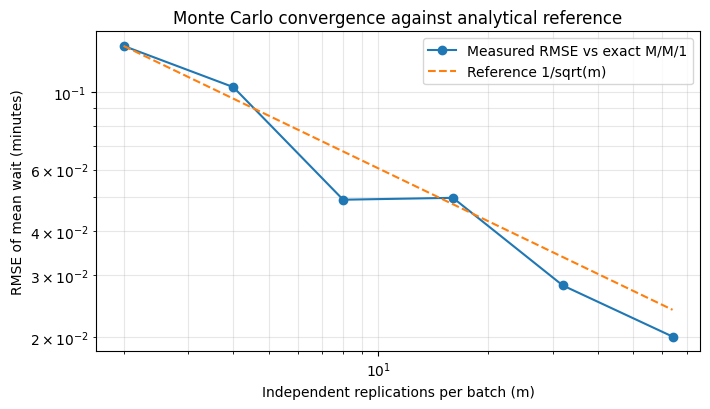

In [10]:
# Direct analytical Monte Carlo error, measured against the exact M/M/1 reference.
def independent_mm1_mean(seed, arrival_rate=.55, service_rate=1.0, warmup=400, recorded=1400):
    rg=random.Random(int(seed));next_arr=0.0;next_free=0.0;total_wait=0.0
    for customer in range(warmup+recorded):
        next_arr+=rg.expovariate(arrival_rate)
        service=rg.expovariate(service_rate)
        wait=max(0.0,next_free-next_arr)
        next_free=max(next_free,next_arr)+service
        if customer>=warmup:total_wait+=wait
    return total_wait/recorded

exact_mm1=mmc_wait(.55,1.0,servers=1)
replication_counts=np.array([2,4,8,16,32,64])
batches=24
error_rows=[]
for m in replication_counts:
    batch_estimates=[]
    for batch in range(batches):
        reps=[independent_mm1_mean(seed=1000000+int(m)*100000+batch*1000+j)
              for j in range(int(m))]
        batch_estimates.append(float(np.mean(reps)))
    batch_estimates=np.array(batch_estimates)
    error_rows.append({'replications':int(m),'rmse_min':float(np.sqrt(np.mean((batch_estimates-exact_mm1)**2))),
                       'bias_min':float(batch_estimates.mean()-exact_mm1)})
error_scaling=pd.DataFrame(error_rows)
display(error_scaling.round(5))
error_scaling.to_csv(RESULTS/'x2_direct_monte_carlo_error.csv',index=False)
slope=float(np.polyfit(np.log(error_scaling.replications),np.log(error_scaling.rmse_min),1)[0])
print(f'Exact M/M/1 Wq: {exact_mm1:.6f} min; measured log-log RMSE slope: {slope:.3f}; theoretical sampling slope: -0.5')
fig,ax=plt.subplots(figsize=(7.2,4.2))
ax.loglog(replication_counts,error_scaling.rmse_min,'o-',label='Measured RMSE vs exact M/M/1')
ax.loglog(replication_counts,error_scaling.rmse_min.iloc[0]*np.sqrt(replication_counts[0]/replication_counts),'--',label='Reference 1/sqrt(m)')
ax.set(xlabel='Independent replications per batch (m)',ylabel='RMSE of mean wait (minutes)',title='Monte Carlo convergence against analytical reference');ax.grid(alpha=.3,which='both');ax.legend();fig.tight_layout()
fig.savefig(FIGURES/'x2_direct_error_scaling.png',dpi=200);plt.show()
# No rigid numerical slope assertion: RMSE is estimated from finite batches and can be noisy.


## 8. Stability-aware systematic sensitivity analysis (X5)

For each independent combination of $\lambda\in\{0.40,0.65,0.85\}$ passengers/minute, $c\in\{1,2,3\}$ stations, and service-time multiplier $f\in\{0.8,1.0,1.2\}$, the nominal utilisation is $\rho=\lambda E[S]f/c$. **Scenarios with $\rho\ge1$ are labelled UNSTABLE**, not assigned a finite steady-state waiting-time estimate.

Keep $\lambda$ fixed when comparing station counts. For each stable combination, use independent seeded replications, discard the initial 400 customers, and construct a 95% Student-$t$ interval for the mean wait. The 30-second threshold is a chosen study target, not a regulatory service level. The printed minimum station count is only conditional on the tested rates and the observed service sample.

,arrival_rate,stations,service_multiplier,nominal_utilisation,status,mean_wait_min,ci_low,ci_high,p_wait_gt_30s
0,0.40,1,0.8,0.3198,STABLE,0.3414,0.3273,0.3555,0.1977
1,0.40,1,1.0,0.3998,STABLE,0.6045,0.5698,0.6391,0.2852
2,0.40,1,1.2,0.4798,STABLE,0.9885,0.9306,1.0465,0.3759
3,0.40,2,0.8,0.1599,STABLE,0.0186,0.0170,0.0201,0.0131
4,0.40,2,1.0,0.1999,STABLE,0.0370,0.0325,0.0415,0.0274
5,0.40,2,1.2,0.2399,STABLE,0.0650,0.0583,0.0717,0.0454
6,0.40,3,0.8,0.1066,STABLE,0.0009,0.0006,0.0011,0.0003
7,0.40,3,1.0,0.1333,STABLE,0.0026,0.0021,0.0032,0.0017
8,0.40,3,1.2,0.1599,STABLE,0.0052,0.0043,0.0061,0.0036
9,0.65,1,0.8,0.5197,STABLE,0.7433,0.7047,0.7820,0.3633


Steady-state estimates intentionally omitted for 1 unstable scenario(s):


,arrival_rate,stations,service_multiplier,nominal_utilisation
20,0.85,1,1.2,1.0195


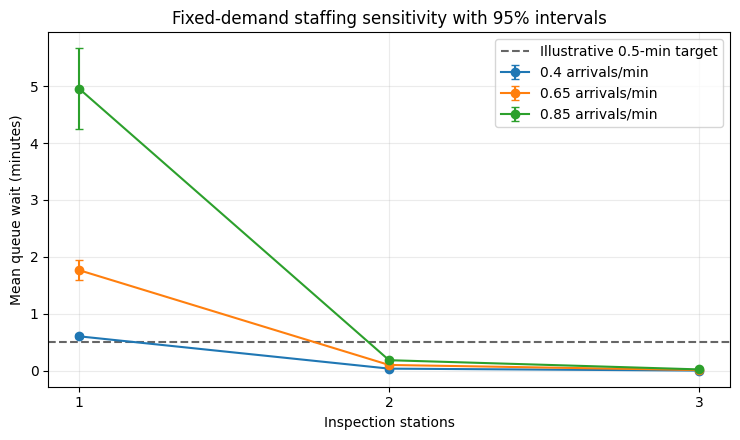

Minimum tested station count with upper 95% CI <=0.5 min at assumed demand of 0.65/min: 2
Model-conditional only: arrivals and server configuration were not observed at Rotterdam.


In [11]:
def empirical_scaled_run(arrival_rate,stations,multiplier,n=1800,warmup=400,seed=0):
    rg=np.random.default_rng(seed)
    arrivals=np.cumsum(rg.exponential(1/arrival_rate,size=n+warmup))
    service=rg.choice(durations_minutes,size=n+warmup,replace=True)*multiplier
    r=simulate(arrivals.tolist(),service.tolist(),servers=stations,target_wait=.5)
    waits=np.asarray(r.waits[warmup:],dtype=float)
    return float(waits.mean()),float((waits>.5).mean())

sensitivity=[]
for lam in [.40,.65,.85]:
 for c in [1,2,3]:
  for multiplier in [.8,1.,1.2]:
   rho=lam*service_mean*multiplier/c
   row={'arrival_rate':lam,'stations':c,'service_multiplier':multiplier,'nominal_utilisation':rho}
   if rho>=1:
    sensitivity.append({**row,'status':'UNSTABLE','mean_wait_min':np.nan,'ci_low':np.nan,'ci_high':np.nan,'p_wait_gt_30s':np.nan})
    continue
   estimates=[empirical_scaled_run(lam,c,multiplier,seed=900000+int(lam*100)*10000+c*1000+int(multiplier*10)*100+j) for j in range(18)]
   wq=mean_ci([v[0] for v in estimates]);tail=np.mean([v[1] for v in estimates])
   sensitivity.append({**row,'status':'STABLE','mean_wait_min':wq[0],'ci_low':wq[1],'ci_high':wq[2],'p_wait_gt_30s':tail})
sensitivity_results=pd.DataFrame(sensitivity)
display(sensitivity_results.round(4))
sensitivity_results.to_csv(RESULTS/'x5_stability_aware_sensitivity.csv',index=False)
unstable=sensitivity_results[sensitivity_results.status=='UNSTABLE']
assert len(unstable)==1,'The expected single overloaded scenario is not found—check assumptions'
print('Steady-state estimates intentionally omitted for',len(unstable),'unstable scenario(s):')
display(unstable[['arrival_rate','stations','service_multiplier','nominal_utilisation']].round(4))
base=sensitivity_results[(sensitivity_results.service_multiplier==1.)&(sensitivity_results.status=='STABLE')].copy()
fig,ax=plt.subplots(figsize=(7.5,4.5))
for demand,g in base.groupby('arrival_rate'):
    g=g.sort_values('stations');ax.errorbar(g.stations,g.mean_wait_min,yerr=[g.mean_wait_min-g.ci_low,g.ci_high-g.mean_wait_min],fmt='o-',capsize=3,label=f'{demand:g} arrivals/min')
ax.axhline(.5,ls='--',color='black',alpha=.6,label='Illustrative 0.5-min target')
ax.set(xlabel='Inspection stations',ylabel='Mean queue wait (minutes)',title='Fixed-demand staffing sensitivity with 95% intervals',xticks=[1,2,3]);ax.legend();ax.grid(alpha=.25);fig.tight_layout()
fig.savefig(FIGURES/'x5_staffing_sensitivity.png',dpi=200);plt.show()
choice=base[base.arrival_rate==.65].sort_values('stations')
passing=choice[choice.ci_high<=.5]
min_c=int(passing.stations.iloc[0]) if len(passing) else None
print('Minimum tested station count with upper 95% CI <=0.5 min at assumed demand of 0.65/min:',min_c)
print('Model-conditional only: arrivals and server configuration were not observed at Rotterdam.')


### Interpretation and uncertainty

The X5 grid separates **demand** (fixed arrival rate), **staffing** (station count), and **service speed** (multiplier). The unstaffable steady-state combination is explicitly identified by $ho\ge1$. Stable cases still have finite-run start-empty bias; intervals reflect simulation variability conditional on the model, not uncertainty in the real arrival rate or queue layout.

For an assumption-robustness check, compare baseline multiplier 1.0 to 0.8 and 1.2 at fixed arrival rate and staffing. The bootstrap intervals in X4 quantify uncertainty in selected observed service durations, while Monte Carlo intervals in X5 measure simulation uncertainty; they answer different questions.

## 9. Discussion, numerical limits and reproducibility

This project calibrates a service-time distribution using **162 positive manual baggage-check durations**, not observed whole-checkpoint arrivals. Demand rates (0.40, 0.65, 0.85 passengers/minute), identical parallel inspection stations and a single FIFO queue are assumed. The selected sample may not generalise to all secondary inspections, and draws may be correlated by operator, passenger or session.

**Verification:** exact manually calculated traces; Python/JavaScript reference traces described in public project tests; independent FIFO waiting-time calculation; analytical M/M/c baseline check; independently simulated M/M/1 RMSE scaling. These checks support correctness **under the specified queue equations**, not empirical validity of a real airport system.

**Statistical precision:** customer waits are serially dependent; the notebook reports t intervals across independent replication estimates. The X4 bootstrap has additional sample-selection and cluster limitations. Finite customer-count simulations with warm-up do not remove all start-empty bias, especially when $ho$ approaches 1. Distinguish Monte Carlo error from data-input uncertainty and model discrepancy.

**Computational cost:** the event-driven method advances only at arrivals and departures. With a small number of stations, its work is approximately linear in customer count times station count; no timestep stability condition applies. $ho<1$ is a queueing *steady-state* condition, not a numerical integrator condition.

**Conclusion rule:** compare station counts at fixed demand, under stable conditions, using a predeclared illustrative target. The resulting staffing conclusion is conditional, not a recommendation for Rotterdam operations.

### Reproducible report outputs

Tables and figures generated above are saved under `Results/` and `Figures/`. The next cell packages them as one ZIP for report preparation. Generated outputs are the evidence for the analyses, not substitutes for the notebook or original data-provenance records.

In [12]:
from zipfile import ZipFile,ZIP_DEFLATED
from pathlib import Path
out_zip=Path('airport_queue_validation_outputs.zip')
with ZipFile(out_zip,'w',ZIP_DEFLATED) as zf:
    for folder in (FIGURES,RESULTS):
        for file in sorted(folder.iterdir()):
            if file.is_file():zf.write(file,arcname=f'{folder.name}/{file.name}')
print(f'Created {out_zip} ({out_zip.stat().st_size:,} bytes) with reproducible figures/tables')


Created airport_queue_validation_outputs.zip (409,884 bytes) with reproducible figures/tables


## 10. References and data attribution

[1] S. Janssen, R. van der Sommen, A. Dilweg, and A. Sharpanskykh, “Data-Driven Analysis of Airport Security Checkpoint Operations,” *Aerospace*, vol. 7, no. 6, Art. 69, 2020. https://doi.org/10.3390/aerospace7060069

[2] S. Janssen et al., *Airport Security Checkpoint Data*, TU Delft / 4TU.ResearchData, 2020. Dataset record: https://research.tudelft.nl/en/datasets/airport-security-checkpoint-data/ (original repository CC BY 4.0).

[3] A. Knol, A. Sharpanskykh, and S. Janssen, “Analyzing Airport Security Checkpoint Performance Using Cognitive Agent Models,” *Journal of Air Transport Management*, vol. 75, pp. 39–50, 2019. https://doi.org/10.1016/j.jairtraman.2018.11.003

[4] J. D. C. Little, “A Proof for the Queuing Formula: $L=\lambda W$,” *Operations Research*, vol. 9, no. 3, pp. 383–387, 1961. https://doi.org/10.1287/opre.9.3.383

[5] D. Gross, J. F. Shortle, J. M. Thompson, and C. M. Harris, *Fundamentals of Queueing Theory*, 4th ed., Wiley, 2008.

[6] A. M. Law, *Simulation Modeling and Analysis*, 5th ed., McGraw-Hill Education, 2015.

[7] P. Heidelberger and P. D. Welch, “Simulation Run Length Control in the Presence of an Initial Transient,” *Operations Research*, vol. 31, no. 6, pp. 1109–1144, 1983. https://doi.org/10.1287/opre.31.6.1109

**Data licence:** CC BY 4.0 applies to the original 4TU observations. Cite the original source and retain the cleaning audit and source-column definitions with the project. Software licensing is distinct from data licensing.